In [1]:
import numpy as np
import pandas as pd


In [3]:
# !pip install gensim

In [4]:
import gensim
import os

In [11]:
from nltk import sent_tokenize
from gensim.utils import simple_preprocess

story=[]
for filename in os.listdir('data'):

    f=open(os.path.join('data',filename))
    corpus=f.read()
    raw_sent=sent_tokenize(corpus)
    for sent in raw_sent:
        story.append(simple_preprocess(sent))

In [12]:
len(story)

158799

In [13]:
model=gensim.models.Word2Vec(
    window=10,
    min_count=2,
    workers=4
)

In [14]:
model.build_vocab(story)

In [15]:
model.train(story,total_examples=model.corpus_count,epochs=model.epochs)

(6569337, 8628190)

In [16]:
model.wv.most_similar('daenerys')

[('stormborn', 0.7692500352859497),
 ('unburnt', 0.7567143440246582),
 ('targaryen', 0.7327193021774292),
 ('elia', 0.7027266621589661),
 ('princess', 0.6978791356086731),
 ('viserys', 0.6658130288124084),
 ('rhaegar', 0.6609048247337341),
 ('myrcella', 0.6597274541854858),
 ('queen', 0.6506746411323547),
 ('aegon', 0.6497193574905396)]

In [17]:
model.wv.doesnt_match(["cersei","jaime","bronn","tyrion"])

'bronn'

In [18]:
model.wv.similarity("arya","sansa")

np.float32(0.825716)

In [23]:
model.wv.get_normed_vectors().shape

(17453, 100)

In [24]:
y=model.wv.index_to_key

In [25]:
y

['the',
 'and',
 'to',
 'of',
 'he',
 'his',
 'was',
 'you',
 'her',
 'in',
 'it',
 'had',
 'that',
 'she',
 'as',
 'with',
 'him',
 'not',
 'but',
 'for',
 'they',
 'is',
 'at',
 'on',
 'said',
 'my',
 'have',
 'be',
 'lord',
 'them',
 'no',
 'from',
 'would',
 'were',
 'me',
 'your',
 'one',
 'all',
 'when',
 'will',
 'ser',
 'if',
 'so',
 'their',
 'we',
 'could',
 'are',
 'man',
 'there',
 'this',
 'up',
 'been',
 'what',
 'did',
 'by',
 'king',
 'do',
 'men',
 'back',
 'out',
 'more',
 'or',
 'who',
 'down',
 'well',
 'than',
 'only',
 'like',
 'jon',
 'some',
 'father',
 'old',
 'hand',
 'even',
 'too',
 'tyrion',
 'before',
 'never',
 'an',
 'off',
 'know',
 'see',
 'into',
 'made',
 'now',
 'eyes',
 'black',
 'told',
 'lady',
 'thought',
 'time',
 'then',
 'how',
 'long',
 'has',
 'can',
 'might',
 'us',
 'come',
 'where',
 'here',
 'through',
 'face',
 'still',
 'head',
 'red',
 'll',
 'way',
 'boy',
 'page',
 'must',
 'once',
 'queen',
 'good',
 'two',
 'brother',
 'night',
 

In [26]:
from sklearn.decomposition import PCA

In [29]:
pca=PCA(n_components=3)

In [30]:
X=pca.fit_transform(model.wv.get_normed_vectors())

In [31]:
X.shape

(17453, 3)

In [35]:
import matplotlib.pyplot as plt

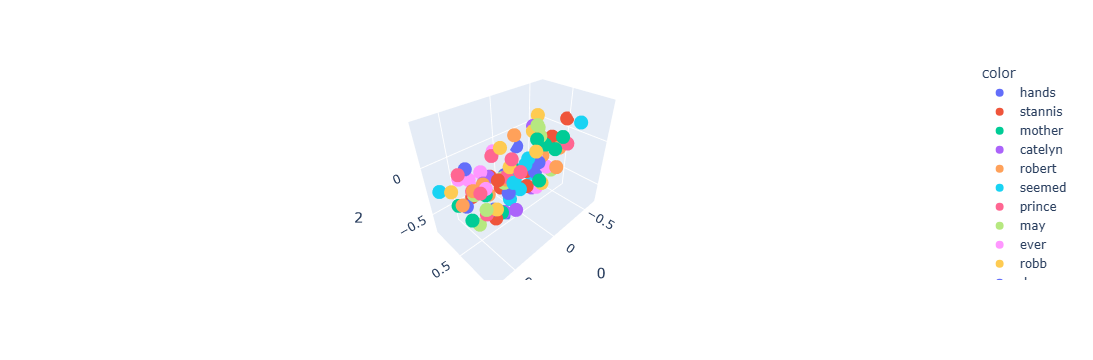

In [37]:
import plotly.express as px
fig=px.scatter_3d(X[200:300],x=0,y=1,z=2,color=y[200:300])
fig.show()